# 01 · Análisis exploratorio de datos (EDA) del dataset FER-2013

**Proyecto:** Emotion Detection Assistant · **Autor:** Edwar Trujillo · **Fase 1**

## ¿Qué es un EDA y para qué sirve?
El **análisis exploratorio de datos** consiste en mirar y medir los datos **antes** de entrenar un modelo.
Un modelo solo puede ser tan bueno como sus datos, así que primero respondemos preguntas como:

1. ¿Cuántas imágenes hay y cómo se reparten entre las 7 emociones? (¿hay **desbalance**?)
2. ¿Qué forma tienen las imágenes? (tamaño, color, rango de valores de los píxeles)
3. ¿Cómo se ven? ¿Qué diferencias visuales hay entre emociones?
4. ¿Hay imágenes repetidas, sobre todo entre *train* y *test*? (riesgo de **fuga de datos**)

Las respuestas justifican decisiones de la fase 2: normalización, *class weights* y *data augmentation*.

## Cómo usar este notebook
- Kernel: **Python 3.11 (emotion-ai)** (arriba a la derecha).
- Ejecuta las celdas **en orden**, de arriba hacia abajo, con **Shift + Enter**.
  Para empezar desde cero: menú **Kernel → Restart Kernel and Run All Cells**.
- Las gráficas se guardan solas en `reports/figures/` y las tablas en `reports/metrics/` (evidencias para el reporte).

## 1. Configuración
Importamos las librerías y definimos rutas y constantes en un solo lugar (**configuración centralizada**:
si algo cambia, se cambia aquí y no en todo el notebook).

- `pathlib.Path`: maneja rutas de archivos de forma segura en Windows y Linux.
- `numpy`: matrices (una imagen es una matriz de números).
- `pandas`: tablas (*DataFrames*) para contar y resumir.
- `matplotlib` / `seaborn`: gráficas.
- `PIL` (Pillow): abrir imágenes.
- `scikit-learn`: calcular los *class weights*.

In [1]:
import hashlib
import json
import random
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image
from sklearn.utils.class_weight import compute_class_weight

# Semilla aleatoria: hace que las muestras "al azar" sean siempre las mismas.
# Así cualquiera que ejecute el notebook obtiene las mismas figuras (reproducibilidad).
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Rutas. Jupyter ejecuta el notebook desde la carpeta notebooks/,
# por eso la raíz del proyecto es la carpeta padre (.parent).
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data" / "fer2013"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
METRICS_DIR = PROJECT_ROOT / "reports" / "metrics"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)  # crea la carpeta si no existe
METRICS_DIR.mkdir(parents=True, exist_ok=True)

# Las 7 clases de FER-2013, en orden alfabético (el mismo orden que usará Keras en la fase 2).
CLASS_NAMES = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]
SPLITS = ["train", "test"]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

# Tamaño de las muestras usadas en los análisis más pesados (para que el notebook sea rápido).
SAMPLES_PER_CLASS_FOR_STATS = 400

sns.set_theme(style="whitegrid")
print("Raíz del proyecto:", PROJECT_ROOT)
print("Carpeta del dataset:", DATA_DIR)

Raíz del proyecto: C:\Users\Personal\Projects\emotion-detection-assistant
Carpeta del dataset: C:\Users\Personal\Projects\emotion-detection-assistant\data\fer2013


## 2. Verificar que el dataset está en su lugar
Antes de analizar, comprobamos la estructura esperada. Si algo falta, el error dice exactamente qué carpeta.

```
data/fer2013/
├── train/  angry, disgust, fear, happy, neutral, sad, surprise
└── test/   (las mismas 7 carpetas)
```

In [2]:
def check_dataset_structure(data_dir: Path) -> None:
    """Verifica que existan train/ y test/ con las 7 carpetas de clases."""
    if not data_dir.is_dir():
        raise FileNotFoundError(
            f"No existe {data_dir}. Descomprime el zip de Kaggle en data/fer2013/ "
            "para que queden data/fer2013/train y data/fer2013/test."
        )
    for split in SPLITS:
        for class_name in CLASS_NAMES:
            class_dir = data_dir / split / class_name
            if not class_dir.is_dir():
                raise FileNotFoundError(f"Falta la carpeta: {class_dir}")
    print("✅ Estructura del dataset correcta")


check_dataset_structure(DATA_DIR)

✅ Estructura del dataset correcta


## 3. Índice de imágenes
Recorremos las carpetas y creamos una tabla con una fila por imagen: **split** (train/test),
**emotion** (la etiqueta, que es el nombre de la carpeta) y **path** (ruta del archivo).
Trabajar con esta tabla es mucho más cómodo que recorrer carpetas cada vez.

In [3]:
records = []
for split in SPLITS:
    for class_name in CLASS_NAMES:
        for file_path in sorted((DATA_DIR / split / class_name).iterdir()):
            if file_path.suffix.lower() in IMAGE_EXTENSIONS:
                records.append({"split": split, "emotion": class_name, "path": file_path})

images_df = pd.DataFrame(records)

print(f"Total de imágenes: {len(images_df):,}")
images_df.groupby("split").size().rename("images").to_frame()

Total de imágenes: 35,887


,images
split,
test,7178
train,28709


## 4. Distribución de clases
Contamos cuántas imágenes hay de cada emoción en *train* y *test*.

**¿Por qué importa?** Si una clase tiene muchas menos imágenes que otras (**desbalance**), el modelo
"aprende" que casi nunca aparece y tiende a no predecirla. Un modelo que nunca dice "disgust" puede tener
buena *accuracy* global y aun así fallar en esa clase. Por eso en la evaluación miraremos métricas
**por clase** (precision, recall, F1), no solo la *accuracy*.

In [4]:
class_counts = (
    images_df.pivot_table(index="emotion", columns="split", values="path", aggfunc="count")
    .reindex(CLASS_NAMES)[SPLITS]
)
class_counts["train_%"] = (class_counts["train"] / class_counts["train"].sum() * 100).round(2)
class_counts["test_%"] = (class_counts["test"] / class_counts["test"].sum() * 100).round(2)

# Evidencia para el reporte: tabla en CSV
class_counts.to_csv(METRICS_DIR / "eda_class_distribution.csv")
class_counts

split,train,test,train_%,test_%
emotion,,,,
angry,3995,958,13.92,13.35
disgust,436,111,1.52,1.55
fear,4097,1024,14.27,14.27
happy,7215,1774,25.13,24.71
neutral,4965,1233,17.29,17.18
sad,4830,1247,16.82,17.37
surprise,3171,831,11.05,11.58


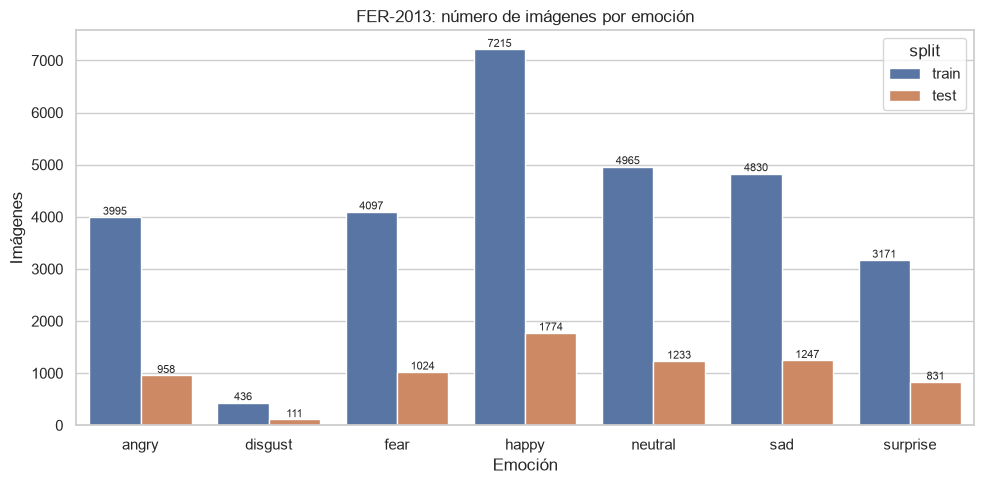

Clase mayoritaria: happy (7,215 imágenes)
Clase minoritaria: disgust (436 imágenes)
Razón de desbalance (mayor / menor): 16.5 a 1


In [5]:
# Gráfica de barras: train y test lado a lado para cada emoción
plot_df = class_counts[SPLITS].reset_index().melt(id_vars="emotion", var_name="split", value_name="images")

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=plot_df, x="emotion", y="images", hue="split", ax=ax)
for container in ax.containers:  # escribe el número encima de cada barra
    ax.bar_label(container, fontsize=8)
ax.set_title("FER-2013: número de imágenes por emoción")
ax.set_xlabel("Emoción")
ax.set_ylabel("Imágenes")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_class_distribution.png", dpi=150)
plt.show()

train_counts = class_counts["train"]
imbalance_ratio = train_counts.max() / train_counts.min()
print(f"Clase mayoritaria: {train_counts.idxmax()} ({train_counts.max():,} imágenes)")
print(f"Clase minoritaria: {train_counts.idxmin()} ({train_counts.min():,} imágenes)")
print(f"Razón de desbalance (mayor / menor): {imbalance_ratio:.1f} a 1")

### 4.1 *Class weights* (pesos por clase)
Una solución al desbalance es darle **más peso** en la función de pérdida a los errores en clases con pocas
imágenes. Así, equivocarse en "disgust" "duele" más que equivocarse en "happy". La fórmula estándar
(`class_weight="balanced"` de scikit-learn) es:

$$w_c = \frac{N}{K \cdot n_c}$$

donde $N$ es el total de imágenes de entrenamiento, $K = 7$ el número de clases y $n_c$ las imágenes de la clase $c$.
Una clase con exactamente el promedio de imágenes recibe peso 1; las más escasas, pesos mayores.

Aquí solo los calculamos para verlos; se usan de verdad en la fase 2 (modelo mejorado).

In [6]:
train_labels = images_df.loc[images_df["split"] == "train", "emotion"].to_numpy()
weights = compute_class_weight(class_weight="balanced", classes=np.array(CLASS_NAMES), y=train_labels)
class_weights_df = pd.DataFrame({"emotion": CLASS_NAMES, "train_images": train_counts.values, "class_weight": weights.round(3)})
class_weights_df.to_csv(METRICS_DIR / "eda_class_weights.csv", index=False)
class_weights_df

,emotion,train_images,class_weight
0,angry,3995,1.027
1,disgust,436,9.407
2,fear,4097,1.001
3,happy,7215,0.568
4,neutral,4965,0.826
5,sad,4830,0.849
6,surprise,3171,1.293


## 5. Propiedades de las imágenes
Una imagen digital es una **matriz de números**. En escala de grises, cada píxel es un entero de
**0 (negro) a 255 (blanco)**. Una imagen de 48x48 es una matriz de 48 filas por 48 columnas: 2.304 números.
(Una imagen a color tendría 3 matrices: rojo, verde y azul.)

Verificamos en **todas** las imágenes que el tamaño y el modo de color sean los esperados.
Pillow solo lee la cabecera del archivo para esto, por eso es rápido. Puede tardar unos segundos.

In [7]:
size_counter = Counter()
mode_counter = Counter()
for image_path in images_df["path"]:
    with Image.open(image_path) as img:
        size_counter[img.size] += 1   # (ancho, alto)
        mode_counter[img.mode] += 1   # "L" = escala de grises (luminancia), "RGB" = color

print("Tamaños encontrados (ancho, alto):", dict(size_counter))
print("Modos de color encontrados:", dict(mode_counter))
if set(size_counter) == {(48, 48)} and set(mode_counter) == {"L"}:
    print("✅ Todas las imágenes son de 48x48 en escala de grises")
else:
    print("⚠️ Hay imágenes con otro tamaño o modo: habrá que convertirlas en el preprocesamiento")

Tamaños encontrados (ancho, alto): {(48, 48): 35887}
Modos de color encontrados: {'L': 35887}
✅ Todas las imágenes son de 48x48 en escala de grises


### 5.1 Una imagen vista como matriz y la normalización
Abajo se ve una imagen y un recorte de 8x8 de su matriz de píxeles.

**Normalización:** antes de entrenar dividimos los píxeles entre 255 para llevarlos al rango **[0, 1]**.
¿Por qué? Las redes neuronales aprenden ajustando pesos con *gradientes*. Con entradas grandes (0-255) los
gradientes también son grandes e inestables, y el entrenamiento oscila o se vuelve lento. Con entradas
pequeñas y en una escala uniforme, el optimizador (Adam) converge más rápido y de forma más estable.

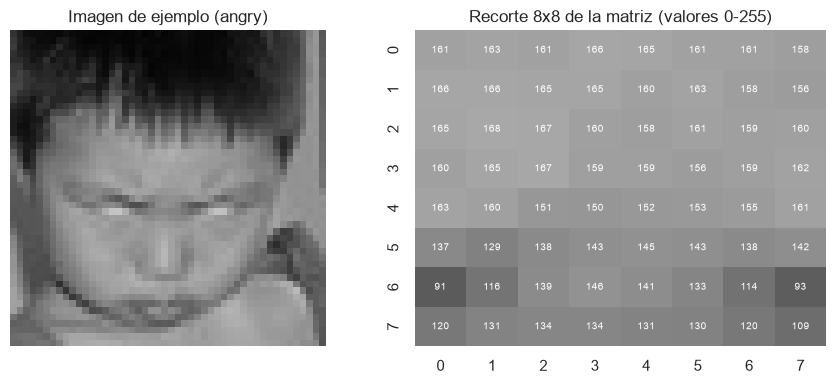

Forma de la matriz: (48, 48) | tipo: uint8
Antes de normalizar: min=3, max=197
Después de normalizar: min=0.012, max=0.773


In [8]:
example_path = images_df.loc[images_df["split"] == "train", "path"].iloc[0]
example_matrix = np.array(Image.open(example_path).convert("L"))  # convert("L") asegura escala de grises

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(example_matrix, cmap="gray", vmin=0, vmax=255)
axes[0].set_title(f"Imagen de ejemplo ({example_path.parent.name})")
axes[0].axis("off")
sns.heatmap(example_matrix[20:28, 20:28], annot=True, fmt="d", cmap="gray", cbar=False,
            vmin=0, vmax=255, ax=axes[1], annot_kws={"fontsize": 7})
axes[1].set_title("Recorte 8x8 de la matriz (valores 0-255)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_image_as_matrix.png", dpi=150)
plt.show()

normalized = example_matrix.astype("float32") / 255.0
print("Forma de la matriz:", example_matrix.shape, "| tipo:", example_matrix.dtype)
print(f"Antes de normalizar: min={example_matrix.min()}, max={example_matrix.max()}")
print(f"Después de normalizar: min={normalized.min():.3f}, max={normalized.max():.3f}")

## 6. Ejemplos de cada emoción
Mostramos 6 imágenes al azar de cada clase (de *train*). Fíjate en cosas que dificultan la tarea:
rostros girados, manos tapando la cara, marcas de agua, imágenes casi idénticas entre clases
(por ejemplo, "fear" y "surprise") y etiquetas que parecen dudosas. Esto explica por qué la precisión
humana en FER-2013 ronda el 65 %.

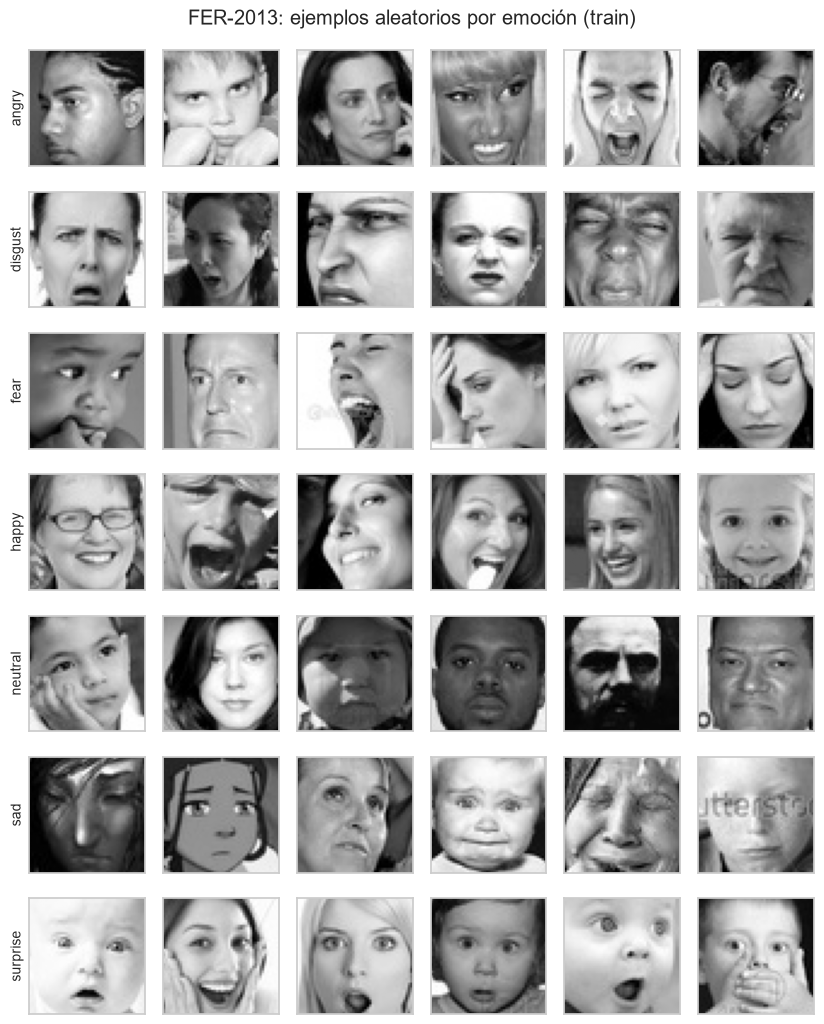

In [9]:
EXAMPLES_PER_CLASS = 6
train_df = images_df[images_df["split"] == "train"]

fig, axes = plt.subplots(len(CLASS_NAMES), EXAMPLES_PER_CLASS, figsize=(EXAMPLES_PER_CLASS * 1.4, len(CLASS_NAMES) * 1.5))
for row, class_name in enumerate(CLASS_NAMES):
    class_paths = train_df.loc[train_df["emotion"] == class_name, "path"]
    sample_paths = class_paths.sample(n=min(EXAMPLES_PER_CLASS, len(class_paths)), random_state=RANDOM_SEED)
    for col, image_path in enumerate(sample_paths):
        ax = axes[row, col]
        ax.imshow(Image.open(image_path).convert("L"), cmap="gray")
        ax.set_xticks([])
        ax.set_yticks([])
        if col == 0:
            ax.set_ylabel(class_name, fontsize=10)
fig.suptitle("FER-2013: ejemplos aleatorios por emoción (train)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_sample_images.png", dpi=150)
plt.show()

## 7. Rostro promedio y estadísticas de píxeles por emoción
Promediamos píxel a píxel unas imágenes de cada clase (máximo 400 por clase, para que sea rápido).
El **rostro promedio** muestra los patrones comunes: por ejemplo, en "happy" suele verse la boca
sonriente y en "surprise" la boca abierta. Esos patrones de bordes y formas son justamente lo que las
capas convolucionales de la CNN aprenden a detectar.

También calculamos el **brillo medio** y la **desviación estándar** (contraste) de cada clase.

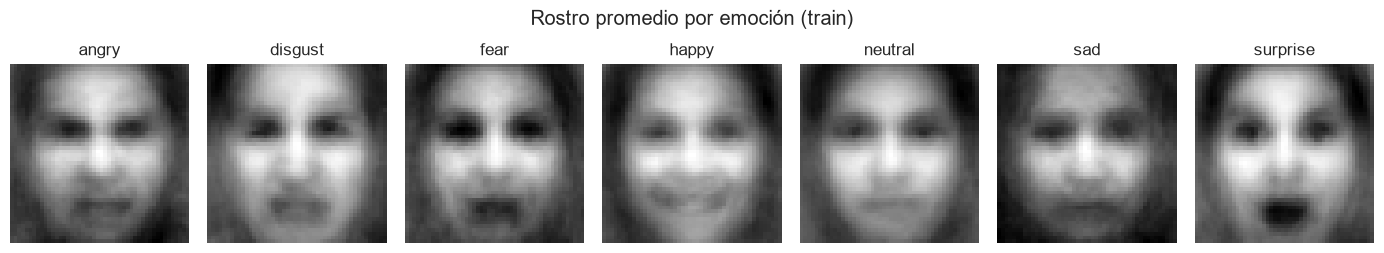

,emotion,sampled_images,mean_brightness,std_contrast
0,angry,400,125.19,65.22
1,disgust,400,135.62,63.60
2,fear,400,136.76,65.38
3,happy,400,128.68,62.85
4,neutral,400,122.19,64.95
5,sad,400,125.14,65.12
6,surprise,400,146.45,64.18


In [10]:
mean_faces = {}
pixel_stats = []
all_sampled_pixels = []

for class_name in CLASS_NAMES:
    class_paths = train_df.loc[train_df["emotion"] == class_name, "path"]
    sample_paths = class_paths.sample(n=min(SAMPLES_PER_CLASS_FOR_STATS, len(class_paths)), random_state=RANDOM_SEED)
    # Apila las imágenes en un arreglo de forma (n_imágenes, 48, 48)
    stack = np.stack([np.array(Image.open(p).convert("L").resize((48, 48)), dtype=np.float32) for p in sample_paths])
    mean_faces[class_name] = stack.mean(axis=0)
    pixel_stats.append({
        "emotion": class_name,
        "sampled_images": len(stack),
        "mean_brightness": round(float(stack.mean()), 2),
        "std_contrast": round(float(stack.std()), 2),
    })
    all_sampled_pixels.append(stack.ravel())

fig, axes = plt.subplots(1, len(CLASS_NAMES), figsize=(14, 2.6))
for ax, class_name in zip(axes, CLASS_NAMES):
    ax.imshow(mean_faces[class_name], cmap="gray")
    ax.set_title(class_name)
    ax.axis("off")
fig.suptitle("Rostro promedio por emoción (train)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_mean_faces.png", dpi=150)
plt.show()

pixel_stats_df = pd.DataFrame(pixel_stats)
pixel_stats_df.to_csv(METRICS_DIR / "eda_pixel_stats.csv", index=False)
pixel_stats_df

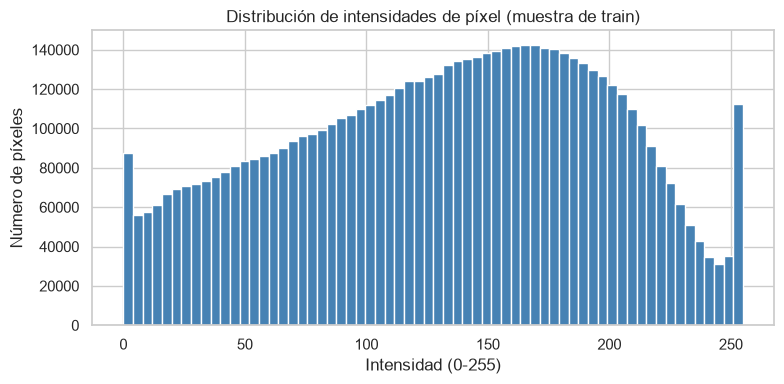

Media global: 131.43 | Desviación estándar: 64.97


In [11]:
# Histograma: cuántos píxeles hay de cada nivel de gris (0 = negro, 255 = blanco)
all_pixels = np.concatenate(all_sampled_pixels)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(all_pixels, bins=64, color="steelblue")
ax.set_title("Distribución de intensidades de píxel (muestra de train)")
ax.set_xlabel("Intensidad (0-255)")
ax.set_ylabel("Número de píxeles")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_pixel_histogram.png", dpi=150)
plt.show()

print(f"Media global: {all_pixels.mean():.2f} | Desviación estándar: {all_pixels.std():.2f}")

## 8. Imágenes duplicadas y fuga de datos
La **fuga de datos** (*data leakage*) ocurre cuando información del conjunto de **test** se cuela en el
entrenamiento. Si la misma imagen está en *train* y en *test*, el modelo ya la "vio", y la accuracy en test
sale **inflada**: parece mejor de lo que es con imágenes nuevas.

Para detectarlo calculamos un **hash MD5** de cada archivo: una "huella digital" de 32 caracteres que es
idéntica solo si los archivos son idénticos byte a byte. Contamos duplicados dentro de cada split y entre splits.
(Esto detecta copias exactas, no fotos parecidas.)

In [12]:
def file_md5(path: Path) -> str:
    """Calcula la huella MD5 del contenido del archivo."""
    return hashlib.md5(path.read_bytes()).hexdigest()


images_df["md5"] = images_df["path"].map(file_md5)

duplicates_within = {
    split: int(images_df[images_df["split"] == split]["md5"].duplicated().sum()) for split in SPLITS
}
train_hashes = set(images_df.loc[images_df["split"] == "train", "md5"])
test_hashes = set(images_df.loc[images_df["split"] == "test", "md5"])
cross_split_duplicates = len(train_hashes & test_hashes)

# Copias exactas con etiquetas distintas: la misma imagen marcada con dos emociones (ruido de etiquetas)
labels_per_hash = images_df.groupby("md5")["emotion"].nunique()
conflicting_labels = int((labels_per_hash > 1).sum())

print(f"Duplicados exactos dentro de train: {duplicates_within['train']:,}")
print(f"Duplicados exactos dentro de test: {duplicates_within['test']:,}")
print(f"Imágenes de test que también están en train: {cross_split_duplicates:,}")
print(f"Imágenes idénticas con etiquetas distintas: {conflicting_labels:,}")

Duplicados exactos dentro de train: 1,236
Duplicados exactos dentro de test: 86
Imágenes de test que también están en train: 531
Imágenes idénticas con etiquetas distintas: 57


## 9. Resumen y evidencias
Guardamos un resumen en JSON con las cifras clave (lo usaremos en el reporte y en `CONTEXTO.md`).

In [13]:
eda_summary = {
    "total_images": int(len(images_df)),
    "images_per_split": {split: int((images_df["split"] == split).sum()) for split in SPLITS},
    "train_images_per_class": {k: int(v) for k, v in train_counts.items()},
    "majority_class": train_counts.idxmax(),
    "minority_class": train_counts.idxmin(),
    "imbalance_ratio": round(float(imbalance_ratio), 2),
    "image_sizes": {f"{w}x{h}": n for (w, h), n in size_counter.items()},
    "color_modes": dict(mode_counter),
    "sample_pixel_mean": round(float(all_pixels.mean()), 2),
    "sample_pixel_std": round(float(all_pixels.std()), 2),
    "duplicates_within_split": duplicates_within,
    "test_images_also_in_train": cross_split_duplicates,
    "identical_images_with_conflicting_labels": conflicting_labels,
}

with open(METRICS_DIR / "eda_summary.json", "w", encoding="utf-8") as f:
    json.dump(eda_summary, f, indent=2, ensure_ascii=False)

print(json.dumps(eda_summary, indent=2, ensure_ascii=False))
print("\nFiguras guardadas en:", FIGURES_DIR)
for figure_path in sorted(FIGURES_DIR.glob("eda_*.png")):
    print("  -", figure_path.name)

{
  "total_images": 35887,
  "images_per_split": {
    "train": 28709,
    "test": 7178
  },
  "train_images_per_class": {
    "angry": 3995,
    "disgust": 436,
    "fear": 4097,
    "happy": 7215,
    "neutral": 4965,
    "sad": 4830,
    "surprise": 3171
  },
  "majority_class": "happy",
  "minority_class": "disgust",
  "imbalance_ratio": 16.55,
  "image_sizes": {
    "48x48": 35887
  },
  "color_modes": {
    "L": 35887
  },
  "sample_pixel_mean": 131.43,
  "sample_pixel_std": 64.97,
  "duplicates_within_split": {
    "train": 1236,
    "test": 86
  },
  "test_images_also_in_train": 531,
  "identical_images_with_conflicting_labels": 57
}

Figuras guardadas en: C:\Users\Personal\Projects\emotion-detection-assistant\reports\figures
  - eda_class_distribution.png
  - eda_image_as_matrix.png
  - eda_mean_faces.png
  - eda_pixel_histogram.png
  - eda_sample_images.png


## 10. Conclusiones y decisiones para la fase 2
Lee las cifras de arriba (sección 9) y verifica que coincidan con estas conclusiones:

1. **Formato:** las imágenes son de 48x48 en escala de grises → la entrada de la CNN será `(48, 48, 1)`,
   con los píxeles **normalizados a [0, 1]**.
2. **Desbalance:** "disgust" tiene muchas menos imágenes que las demás clases → en el modelo mejorado
   usaremos **class weights** y evaluaremos con **precision, recall y F1 por clase** y **matriz de confusión**.
3. **Variabilidad y ruido:** poses, iluminación, oclusiones y etiquetas dudosas → **data augmentation**
   (rotaciones pequeñas, volteo horizontal, zoom) para que el modelo generalice, y una meta realista de
   **68-70 % de accuracy**.
4. **Fuga de datos:** el conjunto de **test no se toca** hasta la evaluación final. Para ajustar el
   entrenamiento (EarlyStopping, ReduceLROnPlateau) separaremos un **conjunto de validación** a partir de *train*.
   Si la sección 8 encontró imágenes de test repetidas en train, lo anotamos como limitación en el reporte.

**Siguiente paso:** fase 2, `02_model_training.ipynb` en Google Colab.